[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Measuring Distance and Area


## What you will be able to do

Measure areas, boundary lengths and distances in kilometers, check them against measurements on the
ellipsoid, and choose a point that is sure to lie inside a shape.

## The idea

### The problem

The forecast office wants three numbers for each district: how large it is, how long its boundary
is, and how far each station is from the office in Oslo. The districts and the stations already hold
every coordinate needed, so each number is one method call away. Whether that number is right depends
on the units the coordinates are in.

Latitude and longitude are angles. A degree of latitude is about 111 kilometers everywhere, while a
degree of longitude is 111 kilometers at the equator, about 56 at Oslo's 60 degrees north, and about 23
at Svalbard's 78. An area computed from raw degrees counts a square degree on Svalbard the same as one in
the south of Norway, though it covers well under half the ground. Asked for an area in degrees,
GeoPandas warns and answers anyway, in square degrees, and the size of a district then depends on how
far north it is.

### A formal definition

> A **planar measurement** treats a geometry's coordinates as positions on a flat plane and measures
> with plane geometry, so its unit is the unit of the CRS. A **geodesic measurement** works on the
> ellipsoid, the slightly flattened sphere that a geographic CRS such as WGS 84 is defined on, and
> measures along its curved surface. GeoPandas' `area`, `length` and `distance` are planar, and
> pyproj's `Geod` is geodesic.

### Why it works that way

GeoPandas hands its measurements to GEOS, which knows only flat geometry. That makes them fast and
exact for the plane, and it puts the work of choosing a sensible plane on the CRS. A projected CRS such
as UTM zone 33N flattens the Earth so that one meter on the map is close to one meter on the ground,
and the error grows with the distance from the zone's central meridian, 15 degrees east. Over Norway
that error is a few tenths of a percent at most, small enough for a district's area or a station's
distance, and this notebook measures it.

The ellipsoid gives the answer the flat measurements approximate. `Geod.inv` returns the distance
between two points along the ellipsoid's surface, and `Geod.geometry_area_perimeter` returns a
polygon's area and perimeter on it, so either can check a planar figure. A centroid is planar too, the
balance point of a shape, and for a shape that curves or comes in pieces it can lie outside the shape
altogether.

### Where this shows up

Every count per square kilometer, every catchment radius and every route length depends on a
measurement like these. The **Coordinate Reference Systems** notebook explains the systems themselves,
and the **Buffers, Overlays and Clipping** notebook draws zones of a given width, which needs the same
care with units.

### What this notebook covers

- areas and boundary lengths of the districts in UTM zone 33N
- distances between the named stations, on the plane and on the ellipsoid
- how much UTM zone 33N stretches distances across Norway
- Norway's area on the ellipsoid and in three projected systems
- centroids and representative points
- three mistakes made when measuring

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point

towns = gpd.GeoSeries([Point(10.75, 59.91), Point(5.32, 60.39)], crs=4326)
in_meters = towns.to_crs(25833)
print(round(in_meters.iloc[0].distance(in_meters.iloc[1]) / 1000, 1), "km from Oslo to Bergen")
```

```
306.7 km from Oslo to Bergen
```

The two towns are converted from degrees to meters in UTM zone 33N, and the distance between them is
then in meters, so dividing by 1,000 gives kilometers.

## Setup

Four libraries for the tables and the geometry, pyproj for measuring on the ellipsoid, Matplotlib for
the map, and two tools from the standard library.

- `warnings` catches the warning in Common errors, so that the cell can print it
- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `numpy` and `pandas` build the made-up register and hold the results
- `geopandas` does the planar measurements, and the cell prints its version
- `shapely` builds the made-up districts, sets the direction of each polygon's rings for the ellipsoid,
  and prints rounded points in Common errors
- `pyproj` measures on the ellipsoid with `Geod`, and reports how much a projection stretches, and the
  cell prints its version
- `matplotlib.pyplot` draws the map of centroids

`countries` holds the outlines of the Nordic countries. Made with Natural Earth. The outlines come
from Natural Earth's 1:50m map of the world's countries, which is in the public domain.

`stations` is the register of 300 weather stations in latitude and longitude, `named` is the five named
stations, and `districts` is the eight forecast districts in meters in UTM zone 33N. The stations and
the districts are made up, drawn from a fixed seed so that they are the same on every run. `geod` is
pyproj's calculator for distances and areas on the WGS 84 ellipsoid.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyproj
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)


districts = forecast_districts()
geod = pyproj.Geod(ellps="WGS84")
print("geopandas", gpd.__version__, "| pyproj", pyproj.__version__, "|", len(stations), "made-up stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | pyproj 3.8.0 | 300 made-up stations, 8 made-up districts


## Worked examples

### Area and boundary length in meters

The districts are in UTM zone 33N, so `area` is in square meters and `length`, which for a polygon is
the length of its boundary, is in meters.

In [2]:
sizes = pd.DataFrame({
    "district": districts["district"],
    "area_km2": (districts.area / 1e6).round(0).astype(int),
    "boundary_km": (districts.length / 1000).round(0).astype(int),
})
sizes

,district,area_km2,boundary_km
0,South,36056,1060
1,East,62504,1177
2,West,53904,2299
3,Mid,61575,2093
4,North,30984,2003
5,Far North,31283,2516
6,Northeast,48523,2482
7,Svalbard,62068,3782


A boundary that follows the coast is long for its area. West's runs 2,299 km around 53,904 km², and
East's, which is mostly inland, 1,177 km around a larger 62,504 km². Every island in the outline adds
its own coastline to the total.

### Distance between points

The named stations are converted to UTM zone 33N, and `distance` measures from every station to Oslo
in meters.

In [3]:
named_m = named.to_crs(25833)
oslo_m = named_m.geometry.iloc[1]
planar_km = (named_m.distance(oslo_m) / 1000).round(1)
planar_km.set_axis(named["name"])

name
Bergen       306.7
Oslo           0.0
Svalbard    2049.6
Tromso      1151.3
Kirkenes    1416.0
dtype: float64

### Distance on the ellipsoid

`geod.inv` takes longitudes and latitudes, longitude first, and returns three arrays: the direction
from the first point toward the second, the direction back, and the distance in meters along the
ellipsoid. It works on whole arrays at once.

In [4]:
oslo = named.iloc[1]
_, _, meters = geod.inv(np.full(5, oslo["longitude"]), np.full(5, oslo["latitude"]),
                        named["longitude"].to_numpy(), named["latitude"].to_numpy())
compare = pd.DataFrame({"planar_km": planar_km.to_numpy(), "geodesic_km": (meters / 1000).round(1)},
                       index=named["name"])
compare["difference_km"] = (compare["planar_km"] - compare["geodesic_km"]).round(1)
compare

,planar_km,geodesic_km,difference_km
name,,,
Bergen,306.7,306.2,0.5
Oslo,0.0,0.0,0.0
Svalbard,2049.6,2050.0,-0.4
Tromso,1151.3,1151.6,-0.3
Kirkenes,1416.0,1415.1,0.9


The two agree to within a kilometer. The plane gives Bergen 0.5 km too far from Oslo and Kirkenes 0.9 km
too far, and gives Tromso and Svalbard a few tenths of a kilometer too close.

### How much UTM zone 33N stretches

`pyproj.Proj(25833).get_factors` reports the projection's scale at a point. 1 means a meter on the map
is a meter on the ground, and 1.003 means the map makes it 3 millimeters longer.

In [5]:
projection = pyproj.Proj(25833)
scale = [projection.get_factors(lon, lat).meridional_scale
         for lon, lat in zip(named["longitude"], named["latitude"])]
pd.Series(np.round(scale, 4), index=named["name"], name="scale")

name
Bergen      1.0031
Oslo        1.0003
Svalbard    0.9996
Tromso      0.9999
Kirkenes    1.0037
Name: scale, dtype: float64

Svalbard, at 15.65 degrees east, is close to the zone's central meridian at 15 degrees, where UTM shrinks
lengths slightly, to 0.9996. Bergen at 5.32 degrees and Kirkenes at 30.05 are farthest from it, and the
map stretches them most, by 0.31% and 0.37%. That is why the plane put those two farther from Oslo. Over
the whole register the largest gap is about a kilometer, as the next cell shows.

In [6]:
planar = stations.to_crs(25833).distance(oslo_m) / 1000
_, _, meters = geod.inv(np.full(len(stations), oslo["longitude"]), np.full(len(stations), oslo["latitude"]),
                        stations["longitude"].to_numpy(), stations["latitude"].to_numpy())
gap = (planar - meters / 1000).abs()
worst = gap.idxmax()
print("largest gap:", round(gap.max(), 1), "km, at", stations.loc[worst, "station"],
      "at", round(stations.loc[worst, "longitude"], 2), "degrees east")
print("largest gap as a share of the distance:", round((gap / (meters / 1000)).max() * 100, 2), "%")

largest gap: 1.0 km, at NS185 at 30.58 degrees east
largest gap as a share of the distance: 0.16 %


### Area on the ellipsoid, and in other systems

`geod.geometry_area_perimeter` measures a polygon in longitude and latitude on the ellipsoid. It counts
an area as positive when the outer ring runs counterclockwise, so `shapely.orient_polygons` turns each
outer ring counterclockwise (and each hole clockwise) first. The cell compares Norway's area there with three projected systems.

In [7]:
norway = countries[countries["ADMIN"] == "Norway"]
area, perimeter = geod.geometry_area_perimeter(shapely.orient_polygons(norway.geometry.iloc[0]))
print("on the ellipsoid:", round(area / 1e6), "km²")
print("without orienting:", round(geod.geometry_area_perimeter(norway.geometry.iloc[0])[0] / 1e6), "km²")
for code in [25833, 3035, 3857]:
    name = pyproj.CRS(code).name
    print(f"EPSG:{code} {name}:", round(norway.to_crs(code).area.iloc[0] / 1e6), "km²")

on the ellipsoid: 386356 km²
without orienting: -386356 km²
EPSG:25833 ETRS89 / UTM zone 33N: 386897 km²
EPSG:3035 ETRS89-extended / LAEA Europe: 386356 km²
EPSG:3857 WGS 84 / Pseudo-Mercator: 3448585 km²


UTM zone 33N gives 386,897 km², 541 km² or 0.14% more than the ellipsoid's 386,356. EPSG:3035, an
equal-area projection for Europe, is built to keep areas, and it agrees with the ellipsoid to the
square kilometer. Web Mercator, the projection of web map tiles, gives 3,448,585 km², nearly nine times
too much, because it stretches everything more the farther it is from the equator, and Svalbard most of
all. The **Coordinate Reference Systems** notebook looks at why.

The districts measured the same two ways differ by less than half a percent.

In [8]:
geodesic = [geod.geometry_area_perimeter(shapely.orient_polygons(shape))[0] / 1e6
            for shape in districts.to_crs(4326).geometry]
sizes.assign(geodesic_km2=np.round(geodesic).astype(int),
             difference_pct=((sizes["area_km2"] - np.array(geodesic)) / np.array(geodesic) * 100).round(2))

,district,area_km2,boundary_km,geodesic_km2,difference_pct
0,South,36056,1060,35925,0.37
1,East,62504,1177,62466,0.06
2,West,53904,2299,53675,0.43
3,Mid,61575,2093,61549,0.04
4,North,30984,2003,31007,-0.07
5,Far North,31283,2516,31287,-0.01
6,Northeast,48523,2482,48349,0.36
7,Svalbard,62068,3782,62099,-0.05


### Centroids and representative points

`centroid` is a shape's balance point. `representative_point` is a point that GEOS guarantees to lie
inside the shape, and is often the better place for a label.

In [9]:
points = districts.assign(centroid=districts.centroid, inside=districts.representative_point())
print(pd.DataFrame({
    "district": points["district"],
    "centroid_inside": points["centroid"].within(points.geometry),
    "representative_inside": points["inside"].within(points.geometry),
    "apart_km": (points["centroid"].distance(points["inside"]) / 1000).round(0).astype(int),
}).to_string(index=False))

 district  centroid_inside  representative_inside  apart_km
    South             True                   True        11
     East             True                   True        16
     West             True                   True        44
      Mid             True                   True        40
    North             True                   True         1
Far North             True                   True        21
Northeast             True                   True        64
 Svalbard             True                   True       143


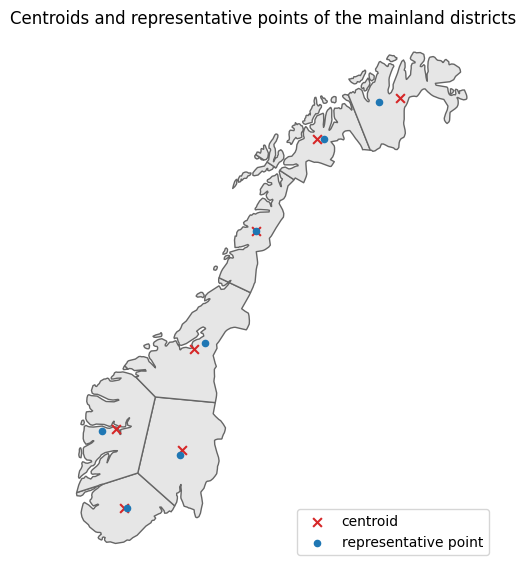

In [10]:
fig, ax = plt.subplots(figsize=(6, 7))
districts.plot(ax=ax, color="0.9", edgecolor="0.4")
points.set_geometry("centroid").plot(ax=ax, color="tab:red", marker="x", markersize=40, label="centroid")
points.set_geometry("inside").plot(ax=ax, color="tab:blue", marker="o", markersize=20,
                                   label="representative point")
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.legend(loc="lower right")
ax.set_axis_off()
ax.set_title("Centroids and representative points of the mainland districts")
plt.show()

Every district's centroid falls inside it, and so does its representative point. The two points lie 1 km
apart in North, 64 km apart in Northeast, and 143 km apart on
Svalbard, whose islands spread far apart. The map leaves out Svalbard to keep the mainland large enough to read.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/06-measuring-distance-and-area-solutions.ipynb).

**1.** Print Norway's boundary length in kilometers in UTM zone 33N and on the ellipsoid, with `geod.geometry_area_perimeter`.

In [11]:
# your code here

**2.** Print the geodesic distance from Tromso to each of the other named stations, in kilometers to one decimal place.

In [12]:
# your code here

**3.** Measure every district's area in EPSG:3035 and print it beside the area in UTM zone 33N.

In [13]:
# your code here

**4.** Find the network station whose distance to Kirkenes differs most between UTM zone 33N and the ellipsoid, and print the gap in kilometers.

In [14]:
# your code here

**5.** Count the network stations that lie within 100 km of their own district's representative point. Join the stations to the districts, then look up each row's representative point by district name.

In [15]:
# your code here

## Common errors

### `UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.`

The districts are converted to latitude and longitude, and their areas taken there.

In [16]:
in_degrees = districts.to_crs(4326)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    square_degrees = in_degrees.area
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message).splitlines()[0]}")
print(pd.DataFrame({"district": districts["district"], "square_degrees": square_degrees.round(2),
                    "km2": (districts.to_crs(25833).area / 1e6).round(0).astype(int)}).to_string(index=False))

 district  square_degrees   km2
    South            5.59 36056
     East           10.25 62504
     West            8.95 53904
      Mid           11.10 61575
    North            6.30 30984
Far North            7.02 31283
Northeast           11.35 48523
 Svalbard           25.78 62068


The numbers come back in square degrees, and they rank the districts wrongly. Svalbard measures 25.78
square degrees, more than twice East's 10.25, though East covers more ground, 62,504 km² against
62,068. A degree of longitude shrinks toward the pole, so a district far north covers less ground for
each square degree. Convert to a projected CRS before measuring, as the worked examples do.

### No error, and a centroid in the sea

In [17]:
norway_m = countries[countries["ADMIN"] == "Norway"].to_crs(25833)
middle = norway_m.centroid
print("centroid:", shapely.to_wkt(middle.to_crs(4326).iloc[0], rounding_precision=2))
print("inside Norway:", middle.within(norway_m.geometry).iloc[0])
print("country it falls in:", gpd.sjoin(gpd.GeoDataFrame(geometry=middle),
                                        countries.to_crs(25833)[["ADMIN", "geometry"]],
                                        how="left")["ADMIN"].iloc[0])
print("km to Norway's outline:", round(middle.iloc[0].distance(norway_m.geometry.iloc[0]) / 1000, 1))
land = mainland_norway()
print("mainland alone, centroid inside:", land.centroid.within(land))

centroid: POINT (12.78 66.37)
inside Norway: False
country it falls in: nan
km to Norway's outline: 13.5
mainland alone, centroid inside: True


Norway's outline is the mainland and Svalbard together, and its balance point lies 13.5 km off the
coast of Nordland, in no country at all. The mainland's own centroid is inside it, so Svalbard is what
pulls the point offshore. Nothing warns, because a centroid is a valid
point. Use `representative_point` when the point has to be inside the shape. For Norway it lands on
Svalbard, which is inside but far from the middle, so for a label on the mainland take the mainland's
part first, with `explode`, which the **Dissolve and Explode** notebook covers.

In [18]:
inside = norway_m.representative_point()
print("representative point:", shapely.to_wkt(inside.to_crs(4326).iloc[0], rounding_precision=2))
print("inside Norway:", inside.within(norway_m.geometry).iloc[0])

representative point: POINT (22.39 79.84)
inside Norway: True


### No error, and Bergen 602.9 km from Oslo

In [19]:
bergen, oslo = named.iloc[0], named.iloc[1]
_, _, swapped = geod.inv(bergen["latitude"], bergen["longitude"], oslo["latitude"], oslo["longitude"])
_, _, correct = geod.inv(bergen["longitude"], bergen["latitude"], oslo["longitude"], oslo["latitude"])
print("latitude first:", round(swapped / 1000, 1), "km")
print("longitude first:", round(correct / 1000, 1), "km")

latitude first: 602.9 km
longitude first: 306.2 km


`geod.inv` takes longitude, then latitude, for each point. Given the latitude first, it reads Bergen as
longitude 60.39 and latitude 5.32, a point in the Indian Ocean, east of Somalia, and measures 602.9 km between two
places that are not Bergen and Oslo. Both sets of numbers are valid coordinates, so nothing fails.
Pass the longitude first, and check one distance you know, such as Oslo to Bergen at about 306 km.

## Recap

- You can measure areas, boundary lengths and distances in kilometers in a projected CRS.
- You can measure distances and areas on the ellipsoid with pyproj's `Geod`, longitude first.
- You can read how much a projection stretches at a point, and say how far a planar figure is off.
- You can tell an equal-area projection from one that inflates area, such as Web Mercator.
- You can choose `representative_point` when a point has to fall inside its shape.

## What is next

The **Spatial Predicates** notebook asks whether shapes lie within, contain, touch or intersect each
other, and shows the spatial index that keeps those questions fast.

---

&#8592; **Previous:** [Reading and Writing Files](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/05-reading-and-writing-files.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Spatial Predicates](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/07-spatial-predicates.ipynb) &#8594;
